In [1]:
import numpy as np

from core.complexes import compute_boundary_matrices, get_C_from_B, get_K_from_B
from core.dynamics import all_partitions
from core.rings import find_what_works_ring, theta_star_from_ring_root, simulate_theta
from core.platonic_solids import make_intro_timeseries_pair, plot_intro_edge_timeseries_stacked

Ring

In [2]:
# Choose a partition
S0_ring = [[1], [2], [3], [4], [5], [6]]
S1_ring = [[1,2], [2,3], [3,4], [4,5], [5,6], [6,1]]
S2_ring = [[1,2,3,4,5,6]]

S_ring = [S0_ring, S1_ring, S2_ring]

ring_partitions = all_partitions(len(S_ring[1]))
S_plus, S_minus = ring_partitions[0] # all-plus partition

# Boundary matrices, C-matrices, unit couplings
boundary_matrices_ring = compute_boundary_matrices(S_ring)

B1r, B2r = boundary_matrices_ring
C1r, C2r = get_C_from_B(B1r, B2r)
K1r, K2r = get_K_from_B(B1r, B2r)

# Find roots
roots_ring = find_what_works_ring(S_plus=S_plus, S_minus=S_minus, B1=B1r, K1=K1r, C1=C1r, z_range=range(-1, 5), verbose=False)

# Simulate dynamics from perturbed fixed points
all_results = []
all_xstars = []

omega = np.zeros(B1r.shape[1])

theta_stars = []
for root in roots_ring:
    z_plus, z_minus, zeta_plus, zeta_minus = root
    theta_star = theta_star_from_ring_root(zeta_minus, S_plus, S_minus, n_edges=6)
    theta_stars.append(theta_star)
    print(theta_star, " winding =", np.sum(theta_star)/(2*np.pi))

sims = []
for i, theta_star in enumerate(theta_stars):
    sol = simulate_theta(theta_star, tmax=20, npts=2500, noise=2e-2, seed=10+i, preserve_sum=True)
    sims.append(sol)

[1.04719755 1.04719755 1.04719755 1.04719755 1.04719755 1.04719755]  winding = 1.0000000000000002
[0. 0. 0. 0. 0. 0.]  winding = 0.0
[-1.04719755 -1.04719755 -1.04719755 -1.04719755 -1.04719755 -1.04719755]  winding = -0.9999999999999999


Figure 1 e

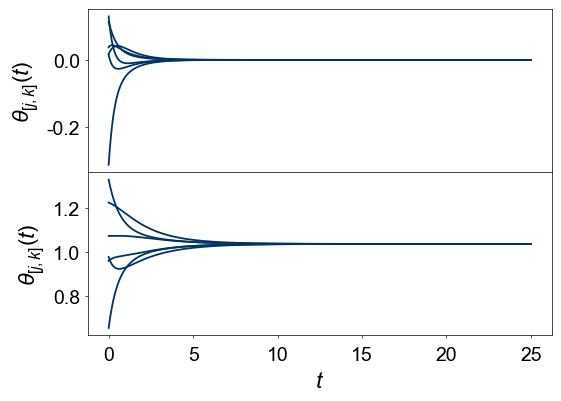

In [3]:
S_plus, S_minus = ring_partitions[0]
theta_star_ring_0 = theta_star_from_ring_root(zeta_minus=0.0, S_plus=S_plus, S_minus=S_minus, n_edges=6)

theta_star_ring_1 = theta_star_from_ring_root(zeta_minus=np.sqrt(3)/2, S_plus=S_plus, S_minus=S_minus, n_edges=6)

sol_ring_0 = simulate_theta(theta_star_ring_0, tmax=25, npts=2000, noise=0.20, seed=1, preserve_sum=True)

sol_ring_1 = simulate_theta(theta_star_ring_1, tmax=25, npts=2000, noise=0.20, seed=2, preserve_sum=True)

ring_data = {"sol1": sol_ring_0, "sol2": sol_ring_1, "info1": {"z_minus": 0, "z_plus": None}, "info2": {"z_minus": 1, "z_plus": None}}

plot_intro_edge_timeseries_stacked(ring_data, save_path="Fig_example_ring_timeseries_final.pdf")

Cube: Fig 1, f

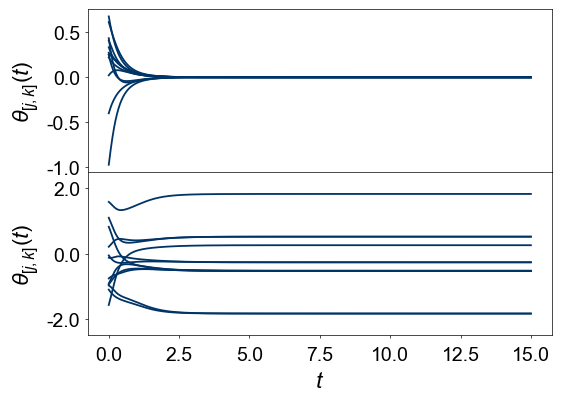

In [3]:
B1c = np.array([
    [-1,  0,  0, +1,  0,  0,  0,  0, -1,  0,  0,  0],
    [+1, -1,  0,  0,  0,  0,  0,  0,  0, -1,  0,  0],
    [ 0, +1, -1,  0,  0,  0,  0,  0,  0,  0, -1,  0],
    [ 0,  0, +1, -1,  0,  0,  0,  0,  0,  0,  0, -1],
    [ 0,  0,  0,  0, -1,  0,  0, +1, +1,  0,  0,  0],
    [ 0,  0,  0,  0, +1, -1,  0,  0,  0, +1,  0,  0],
    [ 0,  0,  0,  0,  0, +1, -1,  0,  0,  0, +1,  0],
    [ 0,  0,  0,  0,  0,  0, +1, -1,  0,  0,  0, +1],
], dtype=int)

B2cT = np.array([
    [+1, +1, +1, +1,  0,  0,  0,  0,  0,  0,  0,  0],
    [ 0,  0,  0,  0, +1, +1, +1, +1,  0,  0,  0,  0],
    [-1,  0,  0,  0, +1,  0,  0,  0, +1, -1,  0,  0],
    [ 0,  0, +1,  0,  0,  0, -1,  0,  0,  0, -1, +1],
    [ 0,  0,  0, +1,  0,  0,  0, -1, +1,  0,  0, -1],
    [ 0, -1,  0,  0,  0, +1,  0,  0,  0, +1, -1,  0],
], dtype=int)

B2c = B2cT.T

cube_data = make_intro_timeseries_pair(B1c, B2c, branch1=(0, 0), branch2=(1, 0), tmax=15, npts=2000, noise=0.75, seed1=1, seed2=2)

plot_intro_edge_timeseries_stacked(cube_data, save_path="Fig_example_cube_timeseries.pdf")